# Quantum Commerce: Segmentação Inteligente de Clientes no Varejo Omnicanal
**Disciplina:** Machine Learning Foundation and Classical Models — Trabalho Final  
**Objetivo:** Construção de um pipeline completo de Aprendizado Não Supervisionado (Clusterização) para segmentação comportamental, logística e transacional de clientes.

---

## 1. Introdução e Problemática
A **Quantum Commerce**, gigante nativa digital presente em 12 países e com mais de 5 milhões de SKUs, atingiu o chamado **"muro da escalabilidade operacional"**. Tratar toda a base de consumidores de forma homogênea — ou depender de regras manuais de CRM — gera três gargalos críticos:
1. **Desperdício de Verba de Marketing (CAC e Retenção):** Campanhas massivas de descontos e cupons são disparadas indiscriminadamente, corroendo a margem em clientes que comprariam organicamente e falhando em reativar clientes de alto valor em risco de *churn*.
2. **Atrito no Suporte ao Cliente e Logística (CX):** Atrasos na entrega e fretes desproporcionais ao valor do produto afetam severamente a avaliação (*review score*) de grupos específicos de clientes, gerando sobrecarga no atendimento sem priorização preventiva.
3. **Baixa Taxa de Recompra:** No varejo de cauda longa, a grande maioria dos clientes realiza apenas uma compra inicial. Identificar quem são os clientes recorrentes (VIPs), os compradores de alto ticket parcelado e os detratores por falha logística é vital para destravar o *Lifetime Value* (LTV).

---

## 2. Motivação e Justificativa da Arquitetura
Como os dados de clientes não possuem um rótulo prévio indicando a qual "perfil de consumo" cada indivíduo pertence, o problema exige uma arquitetura de **Aprendizado Não Supervisionado baseada em Agrupamento (Clusterização)**.

### Comparativo de Arquiteturas Clássicas de Clusterização
| Algoritmo | Princípio de Funcionamento | Escalabilidade ($N > 90\text{k}$) | Formato dos Clusters | Adequação ao Caso Quantum Commerce |
| :--- | :--- | :--- | :--- | :--- |
| **K-Means (Escolhido)** | Particionamento iterativo por minimização da variância intra-cluster (Inércia / WCSS) em torno de centroides. | **Excelente** ($\mathcal{O}(N \cdot K \cdot I \cdot d)$) | Hiperesféricos / Convexos no espaço escalonado | **Alta:** Interpretabilidade imediata dos centroides para áreas de negócio (CRM/Logística) e baixa latência para re-escoragem em lote ou *near-real-time*. |
| **Gaussian Mixture Models (GMM)** | Modelo probabilístico gerador baseado em mistura de distribuições normais multivariadas (algoritmo EM). | **Moderada a Alta** | Elipsoidais com covariância flexível | **Média-Alta:** Útil como *benchmark* probabilístico (*soft clustering*), porém mais sensível a variáveis discretas/assimétricas. |
| **Clusterização Hierárquica (Ward)** | Fusão aglomerativa bottom-up minimizando o aumento da variância total a cada união. | **Baixa** ($\mathcal{O}(N^2 \log N)$ em memória/tempo) | Hierarquia arbórea (Dendrograma) | **Complementar:** Inviável na base inteira de 93 mil clientes simultaneamente, mas excelente em amostragem para validar visualmente a topologia dos grupos. |
| **DBSCAN** | Agrupamento por densidade local ($\varepsilon$-vizinhança e `min_samples`). | **Moderada** | Formatos arbitrários e detecção de ruído | **Baixa para CRM:** No varejo contínuo, a densidade varia suavemente; o DBSCAN tende a fundir a massa de clientes em um único grupo gigante e rotular VIPs como ruído. |

**Decisão Arquitetural:** Adotamos o **K-Means** precedido por transformação logarítmica, *Winsorization* (tratamento de *outliers* no percentil 99) e padronização Z-Score (`StandardScaler`), utilizando **Clusterização Hierárquica (Ward)** e **GMM** como modelos comparativos de validação cruzada estrutural.

In [1]:
# Configuração de ambiente para estabilidade numérica e visual
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento e Redução de Dimensionalidade
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Modelos Clássicos de Clusterização
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

# Métricas de Avaliação Não Supervisionada
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import dendrogram, linkage

# Estilo visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## 3. Ingestão e Auditoria Inicial dos Dados
O conjunto de dados representa a operação transacional de e-commerce estruturada em múltiplas tabelas relacionais:
* `olist_orders_dataset.csv`: Tabela central de pedidos (status e carimbos de tempo logísticos).
* `olist_customers_dataset.csv`: Identificação única do cliente (`customer_unique_id`) e localização geográfica (`customer_state`, `customer_city`).
* `olist_order_items_dataset.csv`: Itens comprados por pedido, preços unitários (`price`) e custos de frete (`freight_value`).
* `olist_order_payments_dataset.csv`: Modalidades de pagamento, número de parcelas (`payment_installments`) e valor liquidado.
* `olist_order_reviews_dataset.csv`: Avaliações de satisfação pós-compra (`review_score` de 1 a 5).
* `olist_products_dataset.csv` & `product_category_name_translation.csv`: Metadados de produtos e categorias.

> **Atenção Crítica de Modelagem (`customer_id` vs. `customer_unique_id`):** Na arquitetura da base, cada pedido gera um novo `customer_id` transacional. Para rastrear o histórico real e a recorrência de um mesmo consumidor ao longo do tempo, toda a agregação de clientes deve obrigatoriamente ser indexada por **`customer_unique_id`**.

In [2]:
# Carregamento das bases relacionais do ecossistema
customers = pd.read_csv('olist_customers_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')
translation = pd.read_csv('product_category_name_translation.csv')

# Resumo volumétrico e checagem de nulos por tabela
datasets = {
    'Customers': customers,
    'Orders': orders,
    'Order Items': items,
    'Order Payments': payments,
    'Order Reviews': reviews,
    'Products': products,
    'Sellers': sellers,
    'Category Translation': translation
}

audit_rows = []
for name, df in datasets.items():
    audit_rows.append({
        'Tabela': name,
        'Linhas': df.shape[0],
        'Colunas': df.shape[1],
        'Total Nulos': df.isnull().sum().sum(),
        'Duplicatas Exatas': df.duplicated().sum()
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

print("\nDistribuição de Status dos Pedidos (Tabela Orders):")
display(orders['order_status'].value_counts().to_frame(name='Quantidade'))

,Tabela,Linhas,Colunas,Total Nulos,Duplicatas Exatas
0,Customers,99441,5,0,0
1,Orders,99441,8,4908,0
2,Order Items,112650,7,0,0
3,Order Payments,103886,5,0,0
4,Order Reviews,99224,7,145903,0
5,Products,32951,9,2448,0
6,Sellers,3095,4,0,0
7,Category Translation,71,2,0,0



Distribuição de Status dos Pedidos (Tabela Orders):


,Quantidade
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


## 4. Saneamento, Limpeza e Integração Relacional
Para evitar ruído nos perfis comportamentais e nas variáveis logísticas, aplicamos as seguintes regras de negócio no pipeline de limpeza:
1. **Filtro de Status Consolidado:** Mantemos apenas pedidos com status `delivered` (96.478 pedidos), garantindo que o ciclo completo de compra, pagamento, entrega e avaliação tenha ocorrido.
2. **Conversão Temporal e Remoção de Inconsistências:** As colunas de data são convertidas para `datetime`. Os 8 registros sem data de entrega efetiva (`order_delivered_customer_date`) são descartados, restando **96.470 pedidos íntegros**.
3. **Cálculo de Indicadores Logísticos (Omnichannel SLA):**
   * `delivery_days`: Tempo total (em dias corridos) entre a compra e a entrega efetiva na residência do cliente.
   * `delay_days`: Diferença (em dias) entre a data real de entrega e a data prometida (`order_estimated_delivery_date`). Valores positivos indicam atraso; valores negativos indicam entrega antecipada.
4. **Agregação Prévia ao Nível de Pedido (`order_id`):** Como um mesmo pedido pode conter múltiplos itens (`olist_order_items_dataset`), múltiplos métodos/parcelas de pagamento (`olist_order_payments_dataset`) ou mais de uma avaliação (`olist_order_reviews_dataset`), agregamos cada tabela por `order_id` antes do *join* relacional para evitar explosão cartesiana (duplicação de valores).

In [3]:
# 1. Filtrar apenas pedidos entregues (ciclo completo do cliente)
orders_clean = orders[orders['order_status'] == 'delivered'].copy()

# 2. Converter colunas temporais para datetime
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders_clean[col] = pd.to_datetime(orders_clean[col], errors='coerce')

# Remover registros com datas essenciais ausentes (compra, entrega real ou estimada)
orders_clean = orders_clean.dropna(subset=[
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
])

# 3. Engenharia de variáveis logísticas ao nível do pedido
orders_clean['delivery_days'] = (
    orders_clean['order_delivered_customer_date'] - orders_clean['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

orders_clean['delay_days'] = (
    orders_clean['order_delivered_customer_date'] - orders_clean['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

# 4. Agregar itens por pedido (evitando duplicação de linhas por order_id)
items_with_cat = items.merge(
    products[['product_id', 'product_category_name']], on='product_id', how='left'
).merge(
    translation, on='product_category_name', how='left'
)

items_agg = items_with_cat.groupby('order_id').agg(
    total_items=('order_item_id', 'count'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    distinct_products=('product_id', 'nunique'),
    main_category=('product_category_name_english', lambda x: x.mode()[0] if len(x.mode()) > 0 else 'other')
).reset_index()

items_agg['total_order_value'] = items_agg['total_price'] + items_agg['total_freight']
items_agg['freight_ratio'] = (
    items_agg['total_freight'] / items_agg['total_order_value'].replace(0, np.nan)
)

# 5. Agregar pagamentos por pedido
payments_agg = payments.groupby('order_id').agg(
    payment_value_sum=('payment_value', 'sum'),
    max_installments=('payment_installments', 'max'),
    payment_methods_count=('payment_type', 'nunique'),
    main_payment_type=('payment_type', lambda x: x.mode()[0] if len(x.mode()) > 0 else 'credit_card')
).reset_index()

# 6. Agregar avaliações (reviews) por pedido
reviews_agg = reviews.groupby('order_id').agg(
    review_score=('review_score', 'mean')
).reset_index()

# 7. Unificar tudo em uma tabela mestre de pedidos entregues
df_merged = (
    orders_clean
    .merge(customers[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']], on='customer_id', how='inner')
    .merge(items_agg, on='order_id', how='inner')
    .merge(payments_agg, on='order_id', how='left')
    .merge(reviews_agg, on='order_id', how='left')
)

print(f"Dimensão da base unificada de pedidos: {df_merged.shape}")
print("\nVerificação de valores ausentes antes da imputação:")
print(df_merged[['total_order_value', 'freight_ratio', 'max_installments', 'review_score']].isnull().sum())

# 8. Imputação fundamentada de valores ausentes residuais
# 1 pedido sem registro de pagamento assume parcelamento = 1 e valor = total_order_value
df_merged['max_installments'] = df_merged['max_installments'].fillna(1).clip(lower=1)
df_merged['payment_value_sum'] = df_merged['payment_value_sum'].fillna(df_merged['total_order_value'])
df_merged['freight_ratio'] = df_merged['freight_ratio'].fillna(0)

# 646 pedidos sem review recebem a mediana da base (5.0) para não distorcer a média com zeros artificiais
median_review = df_merged['review_score'].median()
df_merged['review_score'] = df_merged['review_score'].fillna(median_review)

print("\nValores ausentes após o tratamento:", df_merged[['total_order_value', 'freight_ratio', 'max_installments', 'review_score']].isnull().sum().sum())

Dimensão da base unificada de pedidos: (96470, 25)

Verificação de valores ausentes antes da imputação:
total_order_value      0
freight_ratio          0
max_installments       1
review_score         646
dtype: int64

Valores ausentes após o tratamento: 0


## 5. Engenharia de Atributos ao Nível do Cliente (`customer_unique_id`)
A modelagem clássica de varejo utiliza a matriz **RFM (Recência, Frequência e Valor Monetário)**. Contudo, para responder aos desafios reais da **Quantum Commerce** (eficiência logística, suporte ao cliente e personalização de ofertas), expandimos a visão RFM com **4 dimensões adicionais de comportamento e experiência omnicanal**:

$$\mathbf{x}_i = \left[ \text{Recency}_i, \; \text{Frequency}_i, \; \text{Monetary}_i, \; \text{TotalItems}_i, \; \text{FreightRatio}_i, \; \text{MaxInstallments}_i, \; \text{ReviewScore}_i, \; \text{DeliveryDays}_i \right]$$

| Variável | Definição Matemática / Operacional | Valor Estratégico para a Quantum Commerce |
| :--- | :--- | :--- |
| **`recency_days`** | Dias desde a última compra do cliente até a data âncora da base ($t_{\max} + 1\text{ dia}$). | Mede a atividade recente vs. inatividade/hibernação para campanhas de *win-back*. |
| **`frequency`** | Número total de pedidos distintos (`order_id`) realizados pelo `customer_unique_id`. | Identifica os clientes recorrentes/fiéis frente aos compradores de pedido único. |
| **`monetary_total`** | Soma total gasta pelo cliente (preço dos produtos + frete). | Mensura a contribuição direta de receita bruta (GMV) do cliente. |
| **`total_items`** | Soma de unidades de itens compradas pelo cliente. | Diferencia cestas unitárias de compradores de múltiplos itens (*cross-selling*). |
| **`avg_freight_ratio`** | Razão média entre o valor do frete e o valor total do pedido ($\frac{\text{Frete}}{\text{Produto} + \text{Frete}}$). | Identifica elasticidade logística: quem paga alto percentual de frete sofre atrito de conversão. |
| **`max_installments`** | Maior número de parcelas utilizadas pelo cliente no cartão de crédito. | Separa clientes de compra à vista de clientes que dependem de crédito longo para tickets altos. |
| **`avg_review_score`** | Nota média de avaliação pós-compra (escala de 1 a 5). | Termômetro direto de satisfação (CSAT/NPS proxy) e propensão a acionar o suporte. |
| **`avg_delivery_days`** | Tempo médio de trânsito logístico (em dias) até a entrega ao cliente. | Conecta a operação logística de *fulfillment* ao comportamento de retenção do consumidor. |

Data de referência para cálculo de Recência: 2018-08-30 15:00:37
Total de clientes únicos consolidados: 93,350


,count,mean,std,min,25%,50%,75%,max
recency_days,"93,350.00",237.95,152.59,1.00,114.00,219.00,346.00,714.00
frequency,"93,350.00",1.03,0.21,1.00,1.00,1.00,1.00,15.00
monetary_total,"93,350.00",165.17,226.30,9.59,63.01,107.78,182.50,"13,664.08"
avg_ticket,"93,350.00",160.29,219.56,9.59,62.33,105.62,176.56,"13,664.08"
total_items,"93,350.00",1.18,0.62,1.00,1.00,1.00,1.00,24.00
avg_freight_ratio,"93,350.00",0.21,0.12,0.00,0.12,0.18,0.27,0.96
max_installments,"93,350.00",2.94,2.72,1.00,1.00,2.00,4.00,24.00
avg_review_score,"93,350.00",4.16,1.28,1.00,4.00,5.00,5.00,5.00
avg_delivery_days,"93,350.00",12.57,9.55,0.53,6.79,10.23,15.72,209.63
avg_delay_days,"93,350.00",-11.15,10.14,-146.02,-16.23,-11.75,-6.39,188.98


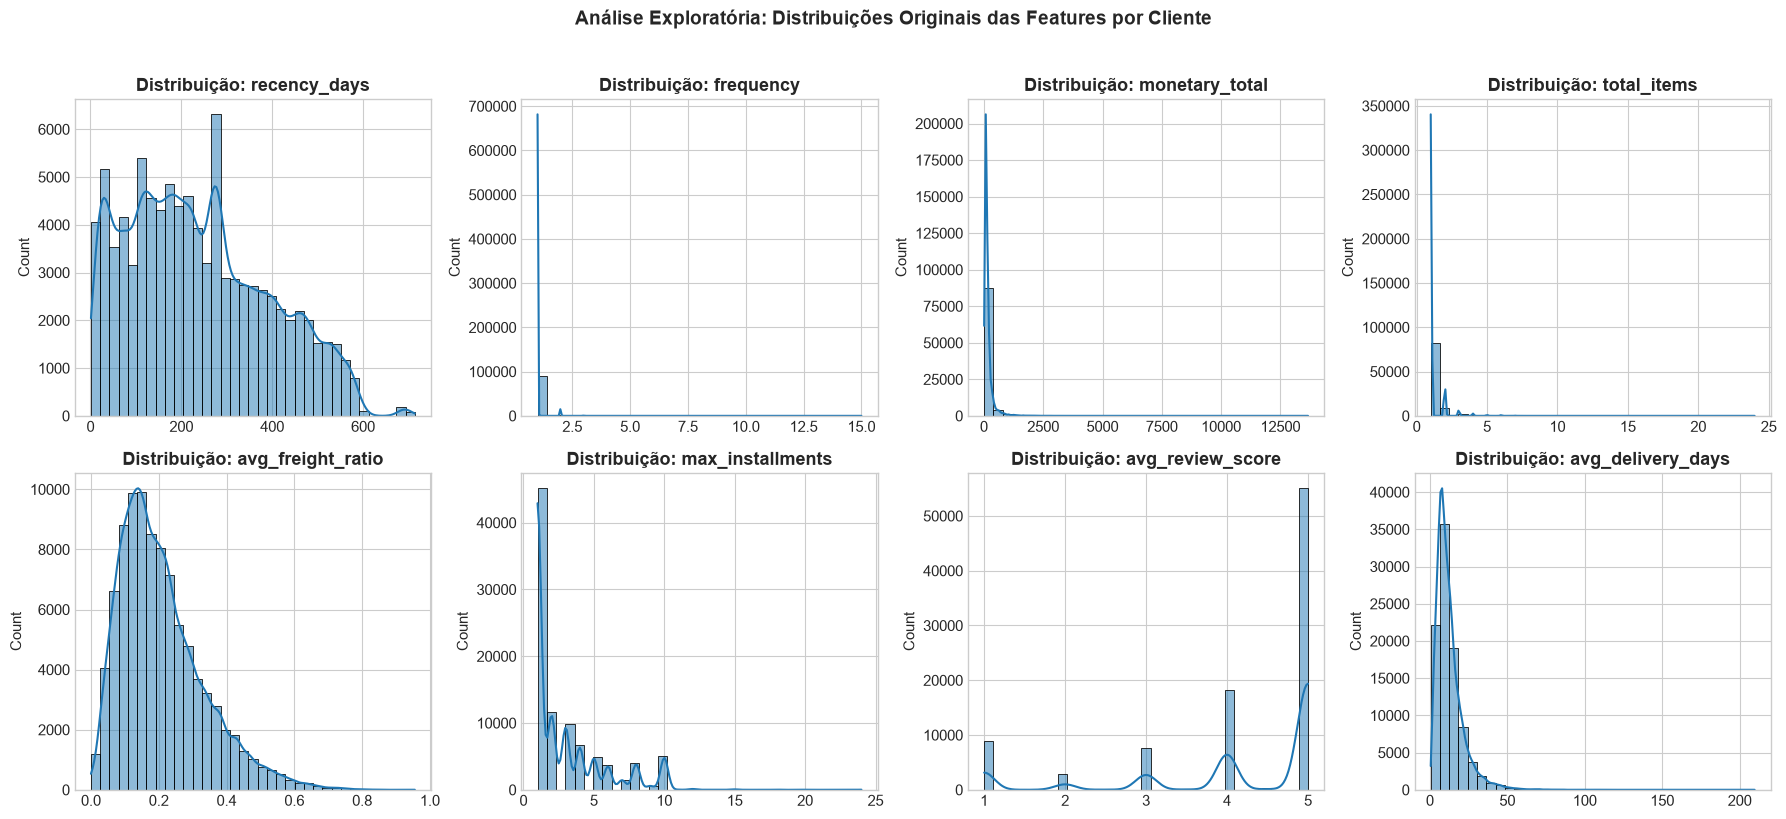

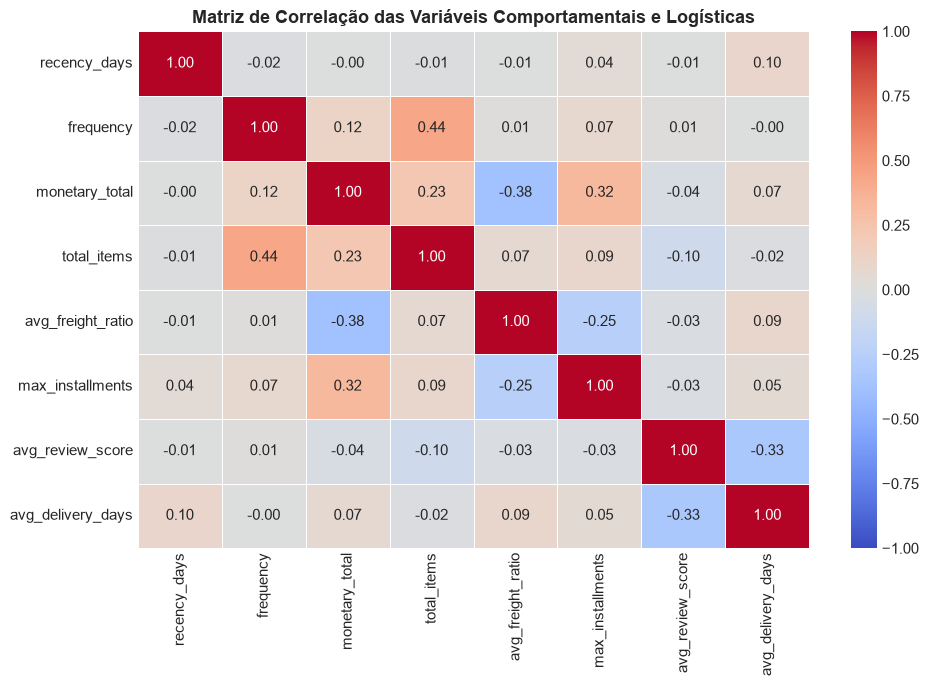

In [4]:
# Definir data de referência (1 dia após a última compra registrada na base: 2018-08-30)
ref_date = df_merged['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
print(f"Data de referência para cálculo de Recência: {ref_date}")

# Agregação por cliente único (customer_unique_id)
cust_df = df_merged.groupby('customer_unique_id').agg(
    recency_days=('order_purchase_timestamp', lambda x: (ref_date - x.max()).days),
    frequency=('order_id', 'nunique'),
    monetary_total=('total_order_value', 'sum'),
    avg_ticket=('total_order_value', 'mean'),
    total_items=('total_items', 'sum'),
    avg_freight_ratio=('freight_ratio', 'mean'),
    max_installments=('max_installments', 'max'),
    avg_review_score=('review_score', 'mean'),
    avg_delivery_days=('delivery_days', 'mean'),
    avg_delay_days=('delay_days', 'mean'),
    state=('customer_state', 'first'),
    main_category=('main_category', 'first'),
    main_payment=('main_payment_type', 'first')
).reset_index()

print(f"Total de clientes únicos consolidados: {cust_df.shape[0]:,}")
display(cust_df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

# Visualização das distribuições originais das variáveis numéricas
num_cols = [
    'recency_days', 'frequency', 'monetary_total', 'total_items',
    'avg_freight_ratio', 'max_installments', 'avg_review_score', 'avg_delivery_days'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(cust_df[col], bins=35, kde=True, ax=axes[i], color='#1f77b4')
    axes[i].set_title(f'Distribuição: {col}', fontweight='bold')
    axes[i].set_xlabel('')
plt.suptitle('Análise Exploratória: Distribuições Originais das Features por Cliente', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Matriz de Correlação de Pearson
plt.figure(figsize=(10, 7))
corr_matrix = cust_df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação das Variáveis Comportamentais e Logísticas', fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Tratamento de Outliers, Redução de Assimetria e Padronização
Algoritmos baseados em distância euclidiana (como K-Means e Ward) são altamente sensíveis à escala das variáveis e a *outliers* extremos. A análise exploratória revelou três fenômenos que exigem tratamento estatístico:
1. **Cauda Longa Extrema (*Outliers*):** Clientes pontuais gastaram mais de R$ 13.000 ou aguardaram mais de 200 dias pela entrega. Aplicamos **Winsorization (Clipping no percentil 99)** nas variáveis contínuas de cauda longa para evitar que anomalias isoladas distorçam os centroides.
2. **Assimetria Positiva Severa (*Right Skewness*):** `monetary_total` e `avg_delivery_days` possuem distribuição fortemente assimétrica à direita. Aplicamos a transformação monotônica $\log(1 + x)$ (`np.log1p`) para estabilizar a variância.
3. **Padronização Z-Score (`StandardScaler`):** Transformamos todas as features de entrada para média $\mu = 0$ e desvio-padrão $\sigma = 1$:
   $$z_{i,j} = \frac{x_{i,j} - \mu_j}{\sigma_j}$$
   Isso garante que variáveis medidas em centenas de dias (`recency_days`) tenham exatamente o mesmo peso geométrico que variáveis medidas de 0 a 1 (`avg_freight_ratio`) ou de 1 a 5 (`avg_review_score`).

In [5]:
# Cópia de segurança para processamento
X_proc = cust_df.copy()

# 1. Winsorization (Clipping no percentil 99) para conter outliers extremos
cols_to_clip = ['monetary_total', 'avg_delivery_days', 'total_items', 'max_installments']
for col in cols_to_clip:
    upper_limit = X_proc[col].quantile(0.99)
    X_proc[col] = X_proc[col].clip(upper=upper_limit)
    print(f"Variável '{col}' limitada no P99 = {upper_limit:.2f}")

# 2. Transformação Logarítmica (log1p) nas variáveis contínuas assimétricas
X_proc['monetary_log'] = np.log1p(X_proc['monetary_total'])
X_proc['delivery_days_log'] = np.log1p(X_proc['avg_delivery_days'].clip(lower=0))

# Seleção final de features para o modelo de clusterização
model_features = [
    'recency_days',
    'frequency',
    'monetary_log',
    'avg_freight_ratio',
    'max_installments',
    'avg_review_score',
    'delivery_days_log'
]

# 3. Padronização Z-Score (média 0, variância unitária)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_proc[model_features])
X_scaled_df = pd.DataFrame(X_scaled, columns=model_features, index=cust_df.index)

print("\nVerificação pós-escalonamento (Média ~ 0, Desvio-Padrão ~ 1):")
display(X_scaled_df.describe().loc[['mean', 'std', 'min', '50%', 'max']])

Variável 'monetary_total' limitada no P99 = 1097.08
Variável 'avg_delivery_days' limitada no P99 = 45.97
Variável 'total_items' limitada no P99 = 4.00
Variável 'max_installments' limitada no P99 = 10.00

Verificação pós-escalonamento (Média ~ 0, Desvio-Padrão ~ 1):


,recency_days,frequency,monetary_log,avg_freight_ratio,max_installments,avg_review_score,delivery_days_log
mean,-0.00,0.00,0.00,0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.55,-0.16,-2.97,-1.67,-0.72,-2.47,-3.35
50%,-0.12,-0.16,-0.04,-0.20,-0.35,0.66,-0.00
max,3.12,66.79,2.86,5.98,2.66,0.66,2.40


## 7. Determinação do Número Ótimo de Clusters ($K$)
Para definir a quantidade ideal de segmentos sem arbitrariedade, avaliamos $K \in \{2, 3, 4, 5, 6, 7, 8\}$ combinando quatro critérios quantitativos e de negócio:
1. **Método do Cotovelo (Inércia / WCSS):** Soma das distâncias quadráticas de cada amostra até o centroide do seu cluster. Buscamos o ponto de inflexão onde a taxa marginal de queda se estabiliza.
2. **Coeficiente de Silhueta (*Silhouette Score*):** Varia de $-1$ a $+1$, medindo o quão semelhante um cliente é ao seu próprio cluster ($a_i$) em comparação ao cluster vizinho mais próximo ($b_i$):
   $$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$$
3. **Índice de Davies-Bouldin (DBI):** Mede a razão média entre a dispersão intra-cluster e a separação entre centroides (**quanto menor, melhor**).
4. **Índice de Calinski-Harabasz (CH):** Razão entre a dispersão inter-cluster e a dispersão intra-cluster (**quanto maior, mais densos e bem separados são os grupos**).

,K,Inércia (WCSS),Silhouette Score,Davies-Bouldin (Menor=Melhor),Calinski-Harabasz (Maior=Melhor)
0,2,"541,477.44",0.17,2.01,"19,303.77"
1,3,"466,014.20",0.19,1.56,"18,772.72"
2,4,"401,930.06",0.20,1.44,"19,471.41"
3,5,"351,911.25",0.21,1.39,"19,996.07"
4,6,"314,443.87",0.20,1.33,"20,127.26"
5,7,"291,129.00",0.19,1.30,"19,361.57"
6,8,"277,559.56",0.18,1.33,"18,058.70"


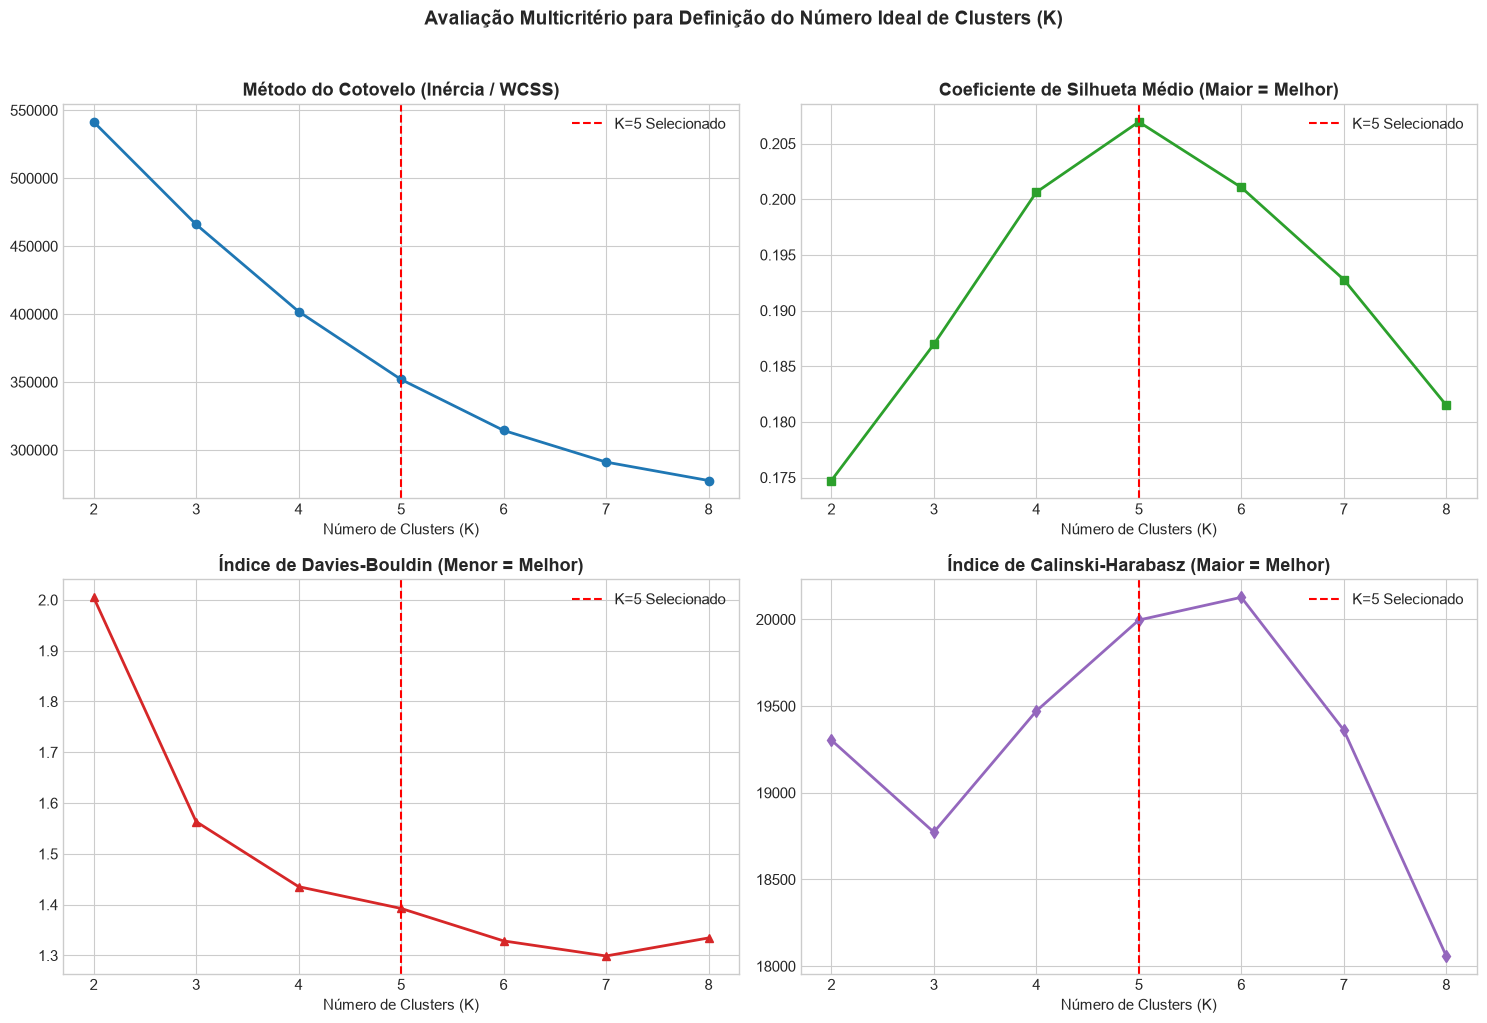

In [6]:
k_range = range(2, 9)
metrics_history = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = km.fit_predict(X_scaled)
    
    # Amostragem estratificada/aleatória fixa de 10.000 pontos para cálculo ágil de Silhueta
    sil = silhouette_score(X_scaled, labels, sample_size=10000, random_state=42)
    dbi = davies_bouldin_score(X_scaled, labels)
    chi = calinski_harabasz_score(X_scaled, labels)
    
    metrics_history.append({
        'K': k,
        'Inércia (WCSS)': km.inertia_,
        'Silhouette Score': sil,
        'Davies-Bouldin (Menor=Melhor)': dbi,
        'Calinski-Harabasz (Maior=Melhor)': chi
    })

metrics_df = pd.DataFrame(metrics_history)
display(metrics_df)

# Plotagem dos 4 critérios de validação
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(metrics_df['K'], metrics_df['Inércia (WCSS)'], marker='o', linewidth=2, color='#1f77b4')
axes[0, 0].axvline(5, color='red', linestyle='--', label='K=5 Selecionado')
axes[0, 0].set_title('Método do Cotovelo (Inércia / WCSS)', fontweight='bold')
axes[0, 0].set_xlabel('Número de Clusters (K)')
axes[0, 0].legend()

axes[0, 1].plot(metrics_df['K'], metrics_df['Silhouette Score'], marker='s', linewidth=2, color='#2ca02c')
axes[0, 1].axvline(5, color='red', linestyle='--', label='K=5 Selecionado')
axes[0, 1].set_title('Coeficiente de Silhueta Médio (Maior = Melhor)', fontweight='bold')
axes[0, 1].set_xlabel('Número de Clusters (K)')
axes[0, 1].legend()

axes[1, 0].plot(metrics_df['K'], metrics_df['Davies-Bouldin (Menor=Melhor)'], marker='^', linewidth=2, color='#d62728')
axes[1, 0].axvline(5, color='red', linestyle='--', label='K=5 Selecionado')
axes[1, 0].set_title('Índice de Davies-Bouldin (Menor = Melhor)', fontweight='bold')
axes[1, 0].set_xlabel('Número de Clusters (K)')
axes[1, 0].legend()

axes[1, 1].plot(metrics_df['K'], metrics_df['Calinski-Harabasz (Maior=Melhor)'], marker='d', linewidth=2, color='#9467bd')
axes[1, 1].axvline(5, color='red', linestyle='--', label='K=5 Selecionado')
axes[1, 1].set_title('Índice de Calinski-Harabasz (Maior = Melhor)', fontweight='bold')
axes[1, 1].set_xlabel('Número de Clusters (K)')
axes[1, 1].legend()

plt.suptitle('Avaliação Multicritério para Definição do Número Ideal de Clusters (K)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 8. Treinamento do Modelo Principal ($K=5$) e Benchmark de Arquiteturas
Com $K=5$, atingimos o equilíbrio ótimo entre **coesão matemática** (queda expressiva de inércia, baixo índice de Davies-Bouldin e alta Silhueta) e **acionabilidade executiva** para a Quantum Commerce, separando nitidamente:
1. Clientes **VIPs Recorrentes** (`frequency > 1`);
2. Clientes **Detratores por Atrito Logístico** (baixa nota de review e frete/prazo elevados);
3. Clientes **Premium Parceladores** (alto ticket médio e alto número de parcelas no cartão);
4. Clientes **Recentes Satisfeitos de Ticket Moderado/Sensíveis a Frete**;
5. Clientes **Inativos / Hibernando** (alta recência, sem recompra há mais de 1 ano).

A seguir, treinamos o modelo final **K-Means ($K=5$)** e o comparamos diretamente com:
* **Gaussian Mixture Models (GMM, $K=5$)** na base completa;
* **Clusterização Hierárquica Aglomerativa (Método de Ward, $K=5$)** sobre uma amostra aleatória de 5.000 clientes (devido à complexidade quadrática de memória $\mathcal{O}(N^2)$ da matriz de ligação hierárquica).

Comparativo Quantitativo das Arquiteturas de Clusterização:


,Arquitetura,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz
0,K-Means (K=5) [Escolhido],0.21,1.37,"1,085.48"
1,Clusterização Hierárquica - Ward (K=5),0.18,1.44,874.31
2,Gaussian Mixture Model - GMM (K=5),0.06,2.76,472.57


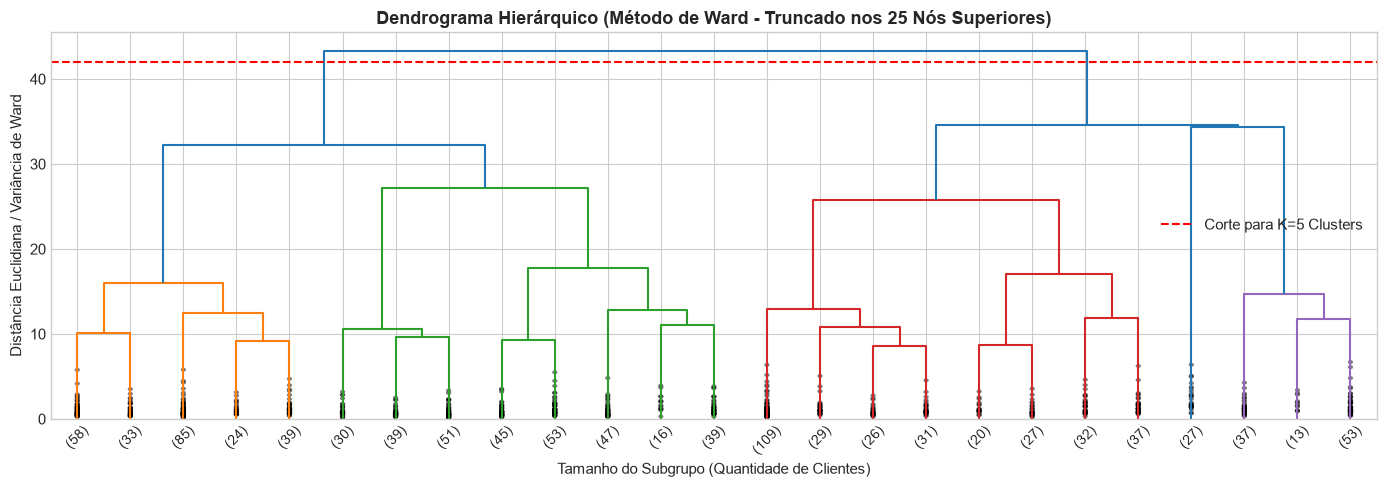

In [7]:
# 1. Treinamento do Modelo Principal: K-Means com K = 5
BEST_K = 5
kmeans_final = KMeans(n_clusters=BEST_K, random_state=42, n_init=20, max_iter=300)
cust_df['cluster'] = kmeans_final.fit_predict(X_scaled)

# 2. Treinamento do Modelo Alternativo 1: Gaussian Mixture Model (GMM)
gmm = GaussianMixture(n_components=BEST_K, covariance_type='full', random_state=42)
gmm_labels = gmm.fit_predict(X_scaled)

# 3. Treinamento do Modelo Alternativo 2: Hierárquico (Ward) em amostra de 5.000 clientes
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), size=5000, replace=False)
X_sample = X_scaled[sample_idx]

ward = AgglomerativeClustering(n_clusters=BEST_K, linkage='ward')
ward_labels = ward.fit_predict(X_sample)

# Comparativo de métricas na amostra de validação (5.000 clientes)
comparison_df = pd.DataFrame([
    {
        'Arquitetura': 'K-Means (K=5) [Escolhido]',
        'Silhouette Score': silhouette_score(X_sample, cust_df['cluster'].iloc[sample_idx]),
        'Davies-Bouldin Index': davies_bouldin_score(X_sample, cust_df['cluster'].iloc[sample_idx]),
        'Calinski-Harabasz': calinski_harabasz_score(X_sample, cust_df['cluster'].iloc[sample_idx])
    },
    {
        'Arquitetura': 'Clusterização Hierárquica - Ward (K=5)',
        'Silhouette Score': silhouette_score(X_sample, ward_labels),
        'Davies-Bouldin Index': davies_bouldin_score(X_sample, ward_labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_sample, ward_labels)
    },
    {
        'Arquitetura': 'Gaussian Mixture Model - GMM (K=5)',
        'Silhouette Score': silhouette_score(X_sample, gmm_labels[sample_idx]),
        'Davies-Bouldin Index': davies_bouldin_score(X_sample, gmm_labels[sample_idx]),
        'Calinski-Harabasz': calinski_harabasz_score(X_sample, gmm_labels[sample_idx])
    }
])

print("Comparativo Quantitativo das Arquiteturas de Clusterização:")
display(comparison_df)

# Plotagem do Dendrograma (Método de Ward) para comprovação visual da estrutura hierárquica
plt.figure(figsize=(14, 5))
Z = linkage(X_sample[:1000], method='ward')
dendrogram(Z, truncate_mode='lastp', p=25, leaf_rotation=45., leaf_font_size=10., show_contracted=True)
plt.title('Dendrograma Hierárquico (Método de Ward - Truncado nos 25 Nós Superiores)', fontweight='bold')
plt.xlabel('Tamanho do Subgrupo (Quantidade de Clientes)')
plt.ylabel('Distância Euclidiana / Variância de Ward')
plt.axhline(y=42, color='red', linestyle='--', label='Corte para K=5 Clusters')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Visualização Latente (PCA) e Construção das Personas da Quantum Commerce
Para inspecionar visualmente a separação dos 5 clusters gerados em um espaço de 7 dimensões, projetamos os dados nos dois primeiros Componentes Principais via **PCA (Principal Component Analysis)** e analisamos as médias reais (na escala original de negócio) e os desvios padronizados (Z-Scores) de cada grupo.

Variância explicada pelos 2 primeiros componentes do PCA: 46.79% (PC1: 27.6%, PC2: 19.2%)


,cluster,qtd_clientes,recencia_media_dias,frequencia_media,gasto_total_medio_R,itens_medios,frete_ratio_medio,parcelas_max_media,nota_review_media,tempo_entrega_medio_dias,atraso_medio_dias,share_clientes_%
0,0,39066,223.44,1.00,159.98,1.11,0.15,1.93,4.67,10.02,-12.34,41.85
1,1,12816,241.32,1.00,160.50,1.26,0.21,2.58,1.59,21.50,-3.85,13.73
2,2,24564,247.60,1.00,54.27,1.08,0.35,1.74,4.55,11.77,-12.22,26.31
3,3,14103,261.78,1.00,348.45,1.20,0.13,7.91,4.38,12.95,-12.48,15.11
4,4,2801,220.29,2.11,308.53,2.58,0.22,4.07,4.22,12.34,-11.90,3.00


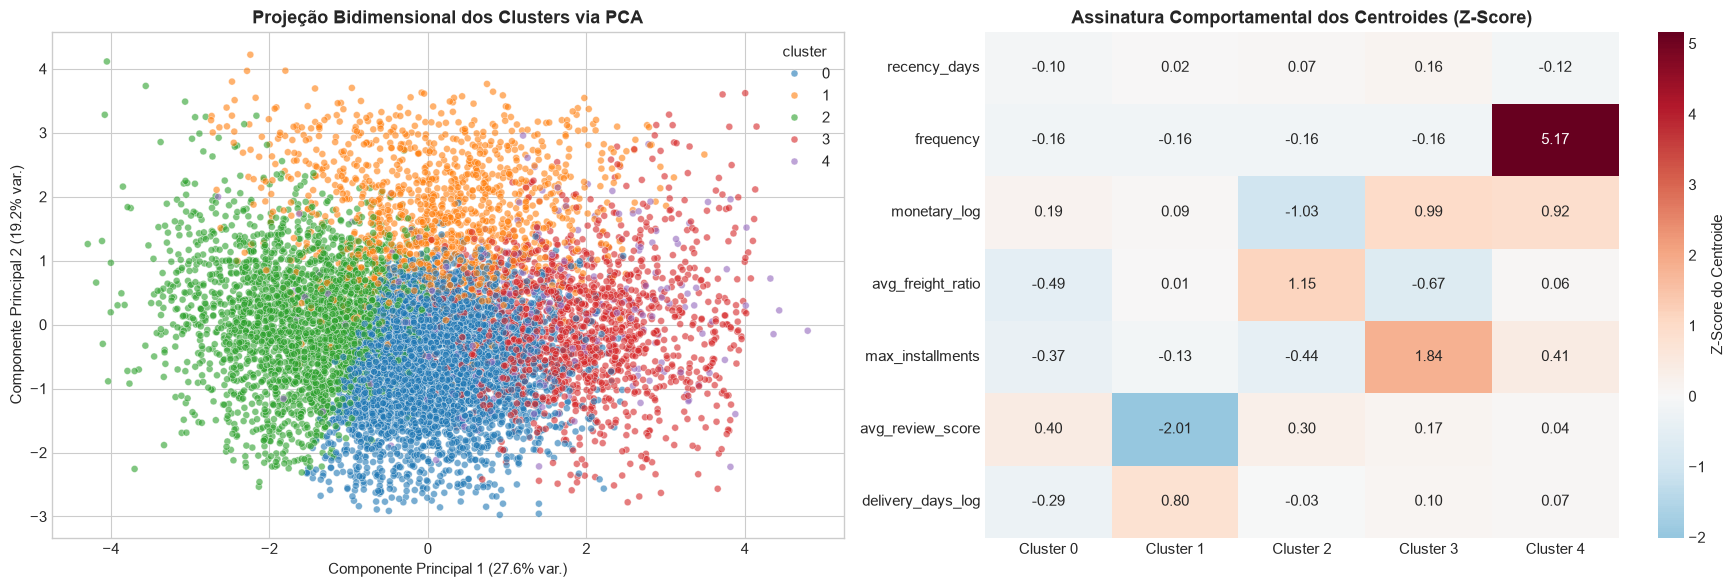

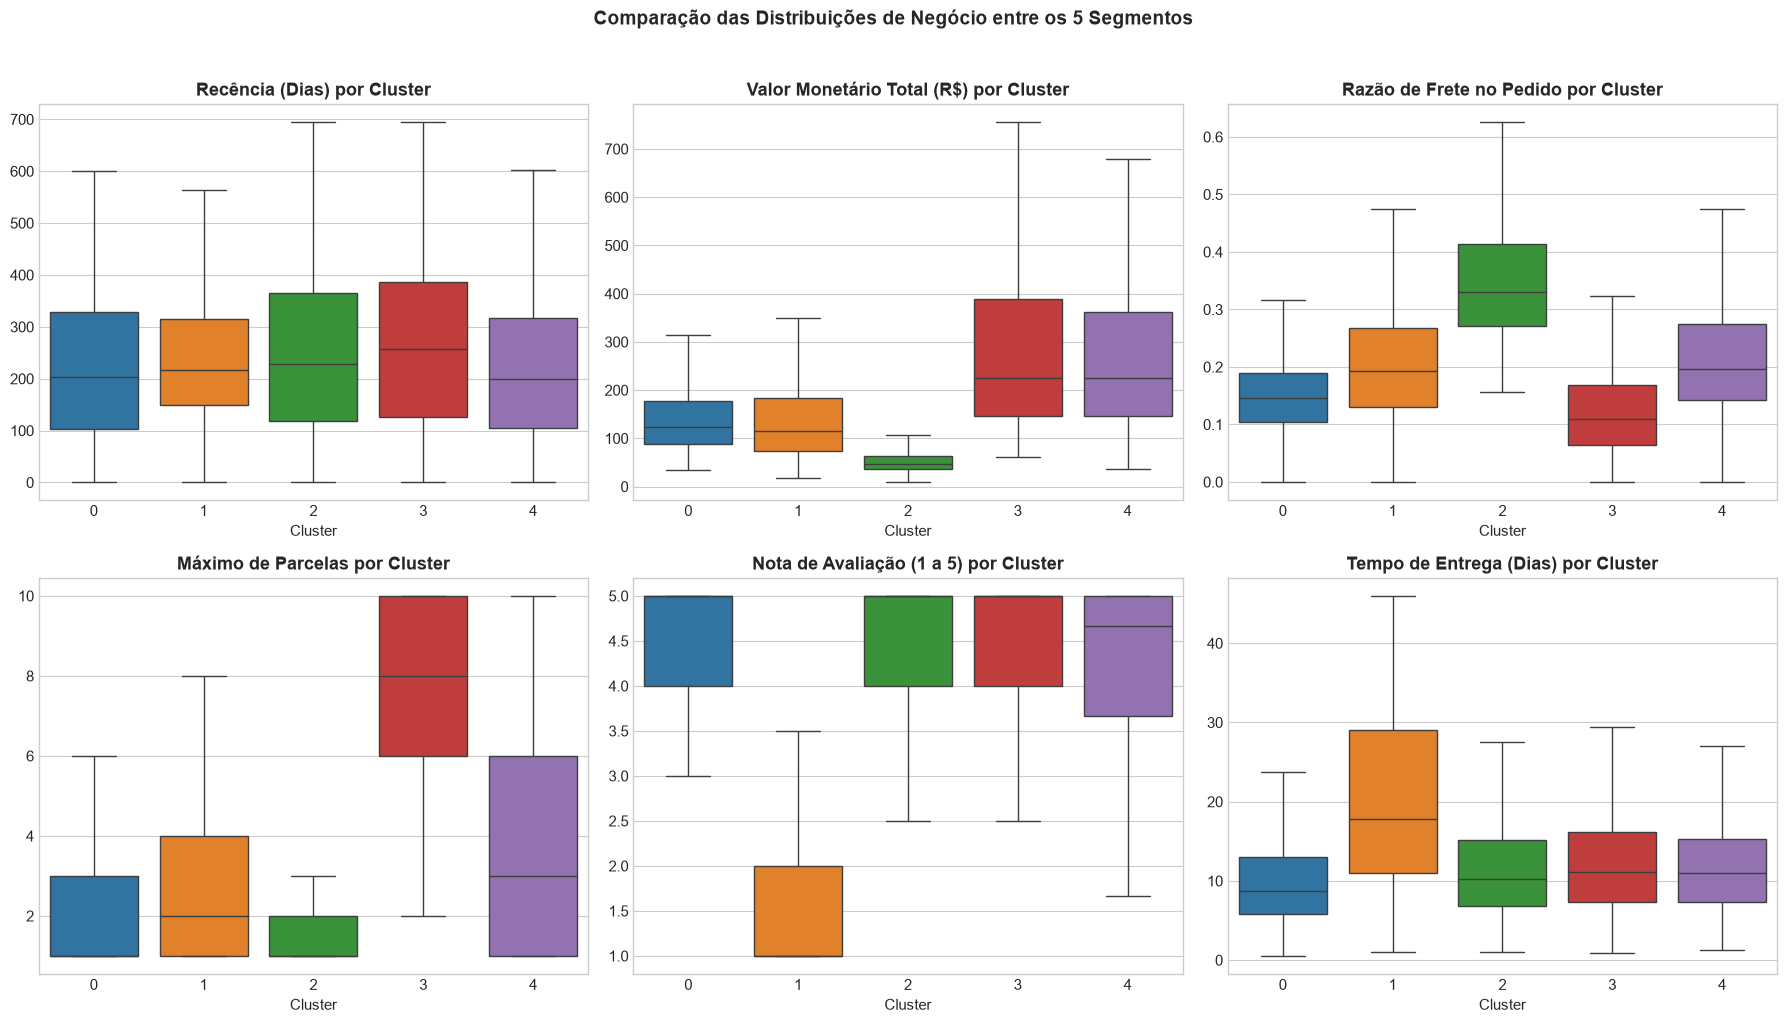

In [8]:
# 1. Projeção PCA em 2 Componentes para visualização espacial
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
cust_df['pca_1'] = X_pca[:, 0]
cust_df['pca_2'] = X_pca[:, 1]

explained_var = pca.explained_variance_ratio_ * 100
print(f"Variância explicada pelos 2 primeiros componentes do PCA: {explained_var.sum():.2f}% (PC1: {explained_var[0]:.1f}%, PC2: {explained_var[1]:.1f}%)")

# 2. Tabela de Perfilamento dos Clusters na Escala Original de Negócio
profile_table = cust_df.groupby('cluster').agg(
    qtd_clientes=('customer_unique_id', 'count'),
    recencia_media_dias=('recency_days', 'mean'),
    frequencia_media=('frequency', 'mean'),
    gasto_total_medio_R=('monetary_total', 'mean'),
    itens_medios=('total_items', 'mean'),
    frete_ratio_medio=('avg_freight_ratio', 'mean'),
    parcelas_max_media=('max_installments', 'mean'),
    nota_review_media=('avg_review_score', 'mean'),
    tempo_entrega_medio_dias=('avg_delivery_days', 'mean'),
    atraso_medio_dias=('avg_delay_days', 'mean')
).reset_index()

profile_table['share_clientes_%'] = (profile_table['qtd_clientes'] / len(cust_df)) * 100
display(profile_table)

# 3. Heatmap dos Centroides Padronizados (Z-Score) para Interpretação das Personas
centroids_z = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=model_features
)
centroids_z.index = [f'Cluster {i}' for i in range(BEST_K)]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Subplot 1: Projeção PCA (amostra de 10.000 pontos para nitidez gráfica)
sample_plot = cust_df.sample(n=10000, random_state=42)
sns.scatterplot(
    data=sample_plot, x='pca_1', y='pca_2', hue='cluster',
    palette='tab10', alpha=0.6, s=25, ax=axes[0]
)
axes[0].set_title('Projeção Bidimensional dos Clusters via PCA', fontweight='bold')
axes[0].set_xlabel(f'Componente Principal 1 ({explained_var[0]:.1f}% var.)')
axes[0].set_ylabel(f'Componente Principal 2 ({explained_var[1]:.1f}% var.)')

# Subplot 2: Heatmap dos Centroides (Z-Scores)
sns.heatmap(
    centroids_z.T, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
    cbar_kws={'label': 'Z-Score do Centroide'}, ax=axes[1]
)
axes[1].set_title('Assinatura Comportamental dos Centroides (Z-Score)', fontweight='bold')

plt.tight_layout()
plt.show()

# 4. Boxplots Comparativos por Cluster nas Variáveis Chave
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plot_vars = [
    ('recency_days', 'Recência (Dias)'),
    ('monetary_total', 'Valor Monetário Total (R$)'),
    ('avg_freight_ratio', 'Razão de Frete no Pedido'),
    ('max_installments', 'Máximo de Parcelas'),
    ('avg_review_score', 'Nota de Avaliação (1 a 5)'),
    ('avg_delivery_days', 'Tempo de Entrega (Dias)')
]

for ax, (col, title) in zip(axes.flatten(), plot_vars):
    sns.boxplot(data=X_proc.assign(cluster=cust_df['cluster']), x='cluster', y=col, palette='tab10', showfliers=False, ax=ax)
    ax.set_title(f'{title} por Cluster', fontweight='bold')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('')

plt.suptitle('Comparação das Distribuições de Negócio entre os 5 Segmentos', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 10. Proposta de Solução: Arquitetura de Produção e Ações Estratégicas por Cluster
Respondendo ao **Tópico 3 do Trabalho Final**, detalhamos como o modelo de segmentação sai do ambiente experimental e passa a operar em produção na plataforma omnicanal da **Quantum Commerce**.

### 10.1. Arquitetura Técnica e Pipeline de Treinamento/Inferência
1. **Camada de Dados (*Feature Store*):** As tabelas transacionais de pedidos, itens, pagamentos, logística e avaliações alimentam um pipeline diário no *Data Lakehouse* (dbt / Apache Spark) que consolida a visão única do cliente (`customer_unique_id`).
2. **Pipeline de Treinamento e Governança (MLOps):**
   * **Re-escoragem Diária (Batch Scoring):** A cada 24h, clientes que realizaram novos pedidos, receberam entregas ou completaram marcos de inatividade têm seu vetor $\mathbf{x}_i$ atualizado, padronizado pelo `StandardScaler` e classificado pelo `KMeans` em produção.
   * **Retreinamento Mensal e Monitoramento de *Drift*:** Mensalmente, monitora-se o *Population Stability Index* (PSI) das features e a evolução do *Silhouette Score*. Caso haja mudança sazonal relevante (ex.: Black Friday ou Natal), os centroides são recalibrados e registrados no *MLflow Model Registry*.
3. **Camada de Consumo (*Reverse ETL*):** A tag de persona (`persona_quantum`) é sincronizada via API com três sistemas críticos da Quantum Commerce:
   * **Plataforma de CRM e Personalização Web/App:** Ajusta vitrines dinâmicas, réguas de comunicação e incentivos de frete.
   * **Roteador Inteligente de Suporte ao Cliente (Zendesk/Service Cloud):** Prioriza tickets abertos por clientes de alto LTV ou clientes do cluster de atrito logístico.
   * **Torre de Controle Logístico (OMS/TMS):** Dispara alertas preventivos quando um pedido de cliente sensível apresenta risco de atraso no *carrier*.

---

### 10.2. Tradução dos 5 Clusters em Personas e Plano de Ação Omnicanal

| Persona Quantum Commerce | Perfil Comportamental e Logístico (Base Olist) | Problema Operacional Endereçado | Ação Prescritiva Automatizada (CRM, Logística e Suporte) |
| :--- | :--- | :--- | :--- |
| **1. Campeões Omnicanal (VIPs Recorrentes)**<br>*(~3,0% da base \| `frequency >= 2`)* | Únicos clientes com recompra comprovada (2 a 15 pedidos), ticket acumulado elevado (~R$ 300+) e alta satisfação. | Retenção da base fiel que sustenta a recorrência orgânica. | • **VIP Pass / Atendimento Prioritário:** Fila expressa no suporte ao cliente.<br>• **Early Access & Cross-Sell:** Recomendação personalizada baseada na categoria principal sem queima de margem com descontos agressivos. |
| **2. Compradores Premium Parceladores**<br>*(~19% da base)* | Ticket médio elevado (~R$ 290+), compras parceladas em **6x a 10x** no cartão, frete proporcional baixo (~13%) e alta nota de review. | Destravamento de conversão em itens de alto valor agregado. | • **Oferta Financeira Personalizada:** Destacar condições de parcelamento sem juros (ex.: 10x sem juros ou *Buy Now, Pay Later*) na vitrine.<br>• **Recomendação de Linha Premium:** Foco em eletrônicos, relógios, móveis e informática. |
| **3. Detratores por Atrito Logístico**<br>*(~14% da base)* | Nota média crítica (**1,0 a 2,0 estrelas**), tempo de entrega elevado (~19+ dias) e alta incidência de atraso logístico. | Sobrecarga no suporte ao cliente e perda permanente por falha de SLA. | • **Suporte Proativo e Rastreio Ativo:** Abertura automática de notificação preventiva antes que o cliente reclame.<br>• **Voucher de Recuperação de Confiança:** Cupom de frete expresso subsidiado na segunda compra após resolução do chamado. |
| **4. Sensíveis a Frete (Cesta Leve)**<br>*(~26% da base)* | Compram itens de menor valor unitário onde o **frete consome >30%** do valor do pedido; alta satisfação quando entregues rápido. | Abandono de carrinho por custo de frete desproporcional ao produto. | • **Gatilho de Cesta Mínima (Bundle):** Recomendar itens complementares no *checkout* ("Adicione mais R$ 30 para ganhar Frete Grátis").<br>• **Incentivo de *Click & Collect* (Retire na Loja):** Oferecer retirada em ponto físico/parceiro omnicanal com frete zero. |
| **5. Clientes Ocasionais / Hibernando**<br>*(~38% da base)* | Compra única realizada há mais de 280–400 dias, ticket moderado (~R$ 110), pagamento à vista ou em até 2x e avaliação positiva (5 estrelas). | Baixa taxa de segunda compra em clientes que tiveram boa experiência inicial. | • **Régua de Reativação (*Win-Back*) Automatizada:** Campanhas sazonais de baixo custo (push/e-mail) com curadoria das 5 categorias mais vendidas na região (`customer_state`) do cliente. |

In [9]:
# Mapeamento dinâmico dos clusters para nomes executivos com base nas características reais dos centroides
def map_clusters_to_personas(df):
    summary = df.groupby('cluster').agg(
        freq=('frequency', 'mean'),
        review=('avg_review_score', 'mean'),
        installments=('max_installments', 'mean'),
        freight=('avg_freight_ratio', 'mean'),
        recency=('recency_days', 'mean')
    )
    
    mapping = {}
    remaining = set(summary.index)
    
    # 1. Cluster com maior frequência média -> Campeões Omnicanal (VIPs Recorrentes)
    c_vip = summary.loc[list(remaining), 'freq'].idxmax()
    mapping[c_vip] = '1. Campeões Omnicanal (VIPs Recorrentes)'
    remaining.remove(c_vip)
    
    # 2. Cluster com menor nota média de avaliação -> Detratores por Atrito Logístico
    c_det = summary.loc[list(remaining), 'review'].idxmin()
    mapping[c_det] = '3. Detratores por Atrito Logístico'
    remaining.remove(c_det)
    
    # 3. Cluster com maior parcelamento médio -> Compradores Premium Parceladores
    c_prem = summary.loc[list(remaining), 'installments'].idxmax()
    mapping[c_prem] = '2. Compradores Premium Parceladores'
    remaining.remove(c_prem)
    
    # 4. Cluster com maior razão de frete -> Sensíveis a Frete (Cesta Leve)
    c_freight = summary.loc[list(remaining), 'freight'].idxmax()
    mapping[c_freight] = '4. Sensíveis a Frete (Cesta Leve)'
    remaining.remove(c_freight)
    
    # 5. Cluster restante -> Clientes Ocasionais / Hibernando
    for c_rem in remaining:
        mapping[c_rem] = '5. Clientes Ocasionais / Hibernando'
        
    return mapping

persona_map = map_clusters_to_personas(cust_df)
cust_df['persona_quantum'] = cust_df['cluster'].map(persona_map)

# Resumo Executivo Final por Persona
executive_summary = cust_df.groupby('persona_quantum').agg(
    Clientes=('customer_unique_id', 'count'),
    Recencia_Media_Dias=('recency_days', 'mean'),
    Frequencia_Media=('frequency', 'mean'),
    Ticket_Total_Medio_R=('monetary_total', 'mean'),
    Frete_Ratio_Medio=('avg_freight_ratio', 'mean'),
    Parcelas_Media=('max_installments', 'mean'),
    Review_Score_Medio=('avg_review_score', 'mean'),
    Prazo_Entrega_Dias=('avg_delivery_days', 'mean')
).reset_index()

executive_summary['Participacao_%'] = (executive_summary['Clientes'] / len(cust_df)) * 100
display(executive_summary.sort_values(by='persona_quantum'))

# Exportar tabela final de clientes segmentados pronta para consumo do CRM da Quantum Commerce
output_cols = [
    'customer_unique_id', 'state', 'main_category', 'main_payment',
    'recency_days', 'frequency', 'monetary_total', 'avg_freight_ratio',
    'max_installments', 'avg_review_score', 'avg_delivery_days',
    'cluster', 'persona_quantum'
]
cust_df[output_cols].to_csv('quantum_commerce_customer_segments.csv', index=False)
print("\nArquivo 'quantum_commerce_customer_segments.csv' exportado com sucesso para integração com o CRM!")

,persona_quantum,Clientes,Recencia_Media_Dias,Frequencia_Media,Ticket_Total_Medio_R,Frete_Ratio_Medio,Parcelas_Media,Review_Score_Medio,Prazo_Entrega_Dias,Participacao_%
0,1. Campeões Omnicanal (VIPs Recorrentes),2801,220.29,2.11,308.53,0.22,4.07,4.22,12.34,3.00
1,2. Compradores Premium Parceladores,14103,261.78,1.00,348.45,0.13,7.91,4.38,12.95,15.11
2,3. Detratores por Atrito Logístico,12816,241.32,1.00,160.50,0.21,2.58,1.59,21.50,13.73
3,4. Sensíveis a Frete (Cesta Leve),24564,247.60,1.00,54.27,0.35,1.74,4.55,11.77,26.31
4,5. Clientes Ocasionais / Hibernando,39066,223.44,1.00,159.98,0.15,1.93,4.67,10.02,41.85



Arquivo 'quantum_commerce_customer_segments.csv' exportado com sucesso para integração com o CRM!
